# ENA_2025_Modulo_08

Partimos del Parquet `08_CAP300AB` y del diccionario ENA 2025.

## 1. Objetivo

Explorar las buenas prácticas agrícolas de la ENA 2025 mediante tablas, gráficos y comparaciones territoriales, utilizando los registros del módulo respectivo.

## 2. Lectura

### 2.1. Importación de librerías

Importamos las librerías necesarias para el análisis y las visualizaciones.

In [127]:
import pandas as pd
import matplotlib.pyplot as plt

### 2.2. Lectura de datos y diccionario

Leemos el archivo Parquet del módulo 08 y su diccionario de variables para realizar los análisis.

In [7]:
# Módulo 08
df_buenas_practicas = pd.read_parquet("../data/raw/2025/08_CAP300AB.parquet")

# Leer el diccionario del módulo 08
df_diccionario_08 = pd.read_excel("../data/raw/excel/DICC_ENA_2025.xlsx", sheet_name="08_CAP300AB")

In [9]:
# Comprobar la lectura del módulo 08
print("Archivo cargado como:", type(df_buenas_practicas).__name__)
print("Filas y columnas:", df_buenas_practicas.shape)

# Comprobar la lectura del diccionario
print("Diccionario cargado como:", type(df_diccionario_08).__name__)

Archivo cargado como: DataFrame
Filas y columnas: (39729, 111)
Diccionario cargado como: DataFrame


In [128]:
print("Filas del diccionario:", len(df_diccionario_08))
print("Columnas del diccionario:", df_diccionario_08.columns.tolist())

Filas del diccionario: 238
Columnas del diccionario: ['Nº', 'NOMBRE DE LA VARIABLE', 'DESCRIPCIÓN DE LAS VARIABLES', 'VALOR', 'TIPO', 'LONGITUD', 'DECIMAL']


## 3. Inspección estructural

### 3.1. Primeras filas y dimensiones

Observamos los primeros registros y dimensiones del módulo 08.

In [15]:
# Primeras filas
display(df_buenas_practicas.head())

# Dimensiones
print("\nFilas y columnas:", df_buenas_practicas.shape)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P327B,P328B,P329B_1,P329B_2,P329B_3,P329B_4,P329B_5,P329B_6,P330B,OMICAP300
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,2,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30002,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,



Filas y columnas: (39729, 111)


### 3.2. Columnas, tipos y valores no nulos
>
Revisamos los nombres de las columnas, sus tipos de datos y la cantidad de valores no nulos.

In [23]:
print("Columnas:", df_buenas_practicas.columns.tolist())
print("\n ")

# Tipos y valores no nulos
df_buenas_practicas.info(verbose=True, show_counts=True)

Columnas: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P301A_1', 'P302A_1', 'P301A_2', 'P302A_2', 'P301A_3', 'P302A_3', 'P301A_4', 'P302A_4', 'P301A_4A', 'P302A_4A', 'P301A_4B', 'P302A_4B', 'P301A_4C', 'P302A_4C', 'P301A_5', 'P302A_5', 'P301A_6', 'P302A_6', 'P301A_7', 'P302A_7', 'P301A_8', 'P302A_8', 'P301A_9', 'P302A_9', 'P301A_10', 'P302A_10', 'P301A_11', 'P302A_11', 'P301A_12', 'P302A_12', 'P301A_12A', 'P302A_12A', 'P301A_12B', 'P302A_12B', 'P301A_12C', 'P302A_12C', 'P301A_13', 'P302A_13', 'P301A_14', 'P302A_14', 'P301A_15', 'P302A_15', 'P301A_16', 'P302A_16', 'P301A_17', 'P302A_17', 'P303B', 'P304B', 'P305B', 'P306B', 'P307B', 'P308B', 'P309B', 'P310B', 'P311B', 'P312B', 'P313B', 'P314B', 'P315B', 'P316B', 'P317B', 'P318B', 'P319B', 'P320B', 'P321B', 'P322B', 'P323B', 'P324B', 'P325B_1', 'P325B_2', 'P325B_3', 'P325B_4', 'P325B_5', 'P

## 4. Unidad de registro e identificadores

### 4.1. Identificación

El proyecto establece una llave compuesta de siete campos para relacionar los módulos de la ENA. Verificamos cuáles están disponibles en el módulo 08 y revisamos la diferencia entre `CLUSTER` y `NSEGM`.

In [35]:
# Llave establecida en el proyecto
llave_oficial = ["ANIO", "CCDD", "CCPP", "CCDI", "CLUSTER", "ID_PROD", "UA"]

# Identificadores disponibles en el módulo 08
print("Columnas del módulo:", df_buenas_practicas.columns.tolist())

# Comparar la llave oficial con las columnas del módulo
print("\nCampos de la llave presentes:", [col for col in llave_oficial if col in df_buenas_practicas.columns])
print("Campos de la llave ausentes:", [col for col in llave_oficial if col not in df_buenas_practicas.columns])

Columnas del módulo: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P301A_1', 'P302A_1', 'P301A_2', 'P302A_2', 'P301A_3', 'P302A_3', 'P301A_4', 'P302A_4', 'P301A_4A', 'P302A_4A', 'P301A_4B', 'P302A_4B', 'P301A_4C', 'P302A_4C', 'P301A_5', 'P302A_5', 'P301A_6', 'P302A_6', 'P301A_7', 'P302A_7', 'P301A_8', 'P302A_8', 'P301A_9', 'P302A_9', 'P301A_10', 'P302A_10', 'P301A_11', 'P302A_11', 'P301A_12', 'P302A_12', 'P301A_12A', 'P302A_12A', 'P301A_12B', 'P302A_12B', 'P301A_12C', 'P302A_12C', 'P301A_13', 'P302A_13', 'P301A_14', 'P302A_14', 'P301A_15', 'P302A_15', 'P301A_16', 'P302A_16', 'P301A_17', 'P302A_17', 'P303B', 'P304B', 'P305B', 'P306B', 'P307B', 'P308B', 'P309B', 'P310B', 'P311B', 'P312B', 'P313B', 'P314B', 'P315B', 'P316B', 'P317B', 'P318B', 'P319B', 'P320B', 'P321B', 'P322B', 'P323B', 'P324B', 'P325B_1', 'P325B_2', 'P325B_3', 'P325B_4', 'P

In [36]:
# Llave candidata
llave_08 = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

print("Llave candidata:", llave_08)
print("Campos disponibles:", all(col in df_buenas_practicas.columns for col in llave_08))

Llave candidata: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'NSEGM', 'ID_PROD', 'UA']
Campos disponibles: True


### 4.2. Valores faltantes

Revisamos los identificadores incompletos y verificamos si existen combinaciones repetidas de la llave candidata y de la identificación de UA.

In [37]:
# Valores nulos por identificador
print(df_buenas_practicas[llave_08].isna().sum())

# Registros con algún identificador faltante
print("\nRegistros incompletos:", df_buenas_practicas[llave_08].isna().any(axis=1).sum())

ANIO          0
CCDD       1343
CCPP       1343
CCDI       1343
NSEGM         0
ID_PROD       0
UA            0
dtype: int64

Registros incompletos: 1343


In [39]:
# Registros con todos los identificadores presentes
df_llave_completa = df_buenas_practicas.dropna(subset=llave_08)

# Combinaciones repetidas de la llave
print("Registros con llave completa:", len(df_llave_completa))
print("Combinaciones repetidas:", df_llave_completa.duplicated(subset=llave_08).sum())

Registros con llave completa: 38386
Combinaciones repetidas: 0


In [41]:
# Identificamos de UA sin ID_PROD
llave_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "UA"]

# Verificamos repetición
repeticiones_ua = df_llave_completa.duplicated(subset=llave_ua, keep=False)

print("Filas con UA repetida:", repeticiones_ua.sum())

# Mostrar registros repetidos
if repeticiones_ua.any():
    display(df_llave_completa.loc[repeticiones_ua, llave_08].head(10))

Filas con UA repetida: 0


### 4.3. Delimitación de registros

Excluimos los registros sin nombre de departamento, comprobamos el año y el resultado final de la encuesta.

In [42]:
# Registros sin departamento
sin_departamento = df_buenas_practicas["NOMBREDD"].isna().sum()

# Copia .capyy para los próximos análisis
df_analisis = df_buenas_practicas[df_buenas_practicas["NOMBREDD"].notna()].copy()

print("Registros sin departamento:", sin_departamento)
print("Registros disponibles para análisis:", len(df_analisis))

Registros sin departamento: 1343
Registros disponibles para análisis: 38386


In [45]:
print("Años:")
print(df_analisis["ANIO"].value_counts(dropna=False))

print("\nResultado final de encuesta:")
print(df_analisis["RESFIN"].value_counts(dropna=False))

Años:
ANIO
2025    38386
Name: count, dtype: int64

Resultado final de encuesta:
RESFIN
1    38386
Name: count, dtype: int64


## 5. Reconocimiento mediante el diccionario

### 5.1. Consulta de variables

Consultamos las descripciones y los valores de las variables seleccionadas en el diccionario.

In [58]:
# Columnas del diccionario
columnas_dic = ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]

# Variables que se consultarán
codigos = [
    "REGION", "NSEGM", "ID_PROD", "UA",
    "P301A_1", "P301A_2", "P301A_3",
    "P301A_9", "P301A_10", "P301A_12A", "P301A_12B",
    "P301A_14", "P301A_15", "P302A_3"
]

In [59]:
# Consultamos las variables y sus filas cercanas
for codigo in codigos:
    indices = df_diccionario_08.index[df_diccionario_08["NOMBRE DE LA VARIABLE"].eq(codigo)]
    print("\nCódigo:", codigo)

    if len(indices):
        i = indices[0]
        display(df_diccionario_08.loc[max(0, i-2):min(len(df_diccionario_08)-1, i+2), columnas_dic])
    else:
        print("No aparece en el diccionario.")


Código: REGION


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
12,NaN,NaN,2 Incompleta
13,NaN,NaN,1 Costa
14,REGION,REGIÓN NATURAL,2 Sierra
15,NaN,NaN,3 Selva
16,ESTRATO,ESTRATO MUESTRAL,NaN



Código: NSEGM


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
5,CCDI,Código del Distrito,NaN
6,NOMBREDI,Nombre del Distrito,NaN
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN



Código: ID_PROD


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN
10,UA,Unidad Agropecuaria N°,NaN
11,RESFIN,Resultado FINAL de la encuesta,1 Completa


... (18 outputs left out)


Código: P301A_15


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
126,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",NaN
127,NaN,"DE: Usar plaguicidas como: Insecticidas, fungi...",NaN
128,P301A_15,NaN,1 Sí
129,NaN,NaN,2 No
130,NaN,¿HACE CUÁNTOS AÑOS LA REALIZA? Usar,NaN



Código: P302A_3


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
44,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",1 Sí
45,P301A_3,DE: Rotar los cultivos para proteger el suelo?,2 No
46,P302A_3,¿HACE CUÁNTOS AÑOS LA REALIZA? Rotar los,NaN
47,NaN,cultivos para proteger el suelo?,NaN
48,NaN,"COMO PRODUCTOR INDEPENDIENTE, ¿LA EMPRESA/UD. ...",NaN


### 5.2. Catálogo de prácticas

Organizamos nueve prácticas agrícolas identificadas en el diccionario, considerando sus códigos, respuestas y condiciones de aplicación.

In [60]:
# Prácticas agrícolas seleccionadas
practicas = {
    "P301A_1": "Análisis de suelos",
    "P301A_2": "Mezclar la tierra con materia orgánica (rastrojos, estiércol, compost, humus, etc.)",
    "P301A_3": "Rotar los cultivos para proteger el suelo",
    "P301A_9": "Determinar la cantidad de agua que necesita su cultivo",
    "P301A_10": "Determinar cada cuánto tiempo debe regar su cultivo",
    "P301A_12A": "Análisis de agua",
    "P301A_12B": "Construcción de diques (solo para la región Sierra)",
    "P301A_14": "Usar fertilizantes",
    "P301A_15": "Usar plaguicidas como: insecticidas, fungicidas, herbicidas, acaricidas, bactericidas, nematicidas, rodenticidas, molusquicidas, etc."
}

In [63]:
condicion_territorial = {"P301A_12B": "Solo Sierra (REGION = 2)"}

catalogo = pd.DataFrame([
    {
        "codigo": codigo,
        "significado": significado,
        "tipo": "categórica binaria",
        "respuestas": "1 = Sí; 2 = No",
        "condicion": condicion_territorial.get(codigo, "Sin restricción territorial indicada")
    }
    for codigo, significado in practicas.items()
])

display(catalogo)

,codigo,significado,tipo,respuestas,condicion
0,P301A_1,Análisis de suelos,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
1,P301A_2,Mezclar la tierra con materia orgánica (rastro...,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
2,P301A_3,Rotar los cultivos para proteger el suelo,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
3,P301A_9,Determinar la cantidad de agua que necesita su...,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
4,P301A_10,Determinar cada cuánto tiempo debe regar su cu...,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
5,P301A_12A,Análisis de agua,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
6,P301A_12B,Construcción de diques (solo para la región Si...,categórica binaria,1 = Sí; 2 = No,Solo Sierra (REGION = 2)
7,P301A_14,Usar fertilizantes,categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada
8,P301A_15,"Usar plaguicidas como: insecticidas, fungicida...",categórica binaria,1 = Sí; 2 = No,Sin restricción territorial indicada


### 5.3. Condiciones de aplicación

Según las indicaciones del diccionario, verificamos las condiciones de aplicación de `P301A_12B` y `P302A_3`.

In [65]:
# Respuestas de P301A_12B por región natural
tabla_sierra = pd.crosstab(
    df_analisis["REGION"],
    df_analisis["P301A_12B"],
    dropna=False
)

display(tabla_sierra)

# Respuestas registradas fuera de Sierra
fuera_sierra = df_analisis[
    (df_analisis["REGION"] != 2) &
    (df_analisis["P301A_12B"].notna())
]

print("\nRespuestas fuera de Sierra:", len(fuera_sierra))

P301A_12B,1.0,2.0,NaN
REGION,,,
1,0,6,8747
2,86,22335,0
3,0,1,7211



Respuestas fuera de Sierra: 7


In [67]:
# Relación entre rotación de cultivos y años reportados
tabla_rotacion = pd.crosstab(
    df_analisis["P301A_3"],
    df_analisis["P302A_3"].notna(),
    dropna=False
)

tabla_rotacion.columns = ["Sin años registrados", "Años registrados"]
display(tabla_rotacion)

# Valores de años entre quienes respondieron Sí
anios_rotacion = df_analisis.loc[
    df_analisis["P301A_3"] == 1, "P302A_3"
]

print("\nRespuestas Sí:", len(anios_rotacion))
print("Años registrados:", anios_rotacion.notna().sum())
print("Años faltantes:", anios_rotacion.isna().sum())

,Sin años registrados,Años registrados
P301A_3,,
1,0,20946
2,17440,0



Respuestas Sí: 20946
Años registrados: 20946
Años faltantes: 0


## 6. Disponibilidad

### 6.1. Frecuencias y valores nulos

Contamos las respuestas Sí (1), No (2), los valores nulos y otros códigos presentes en cada práctica.

In [68]:
# Frecuencias de las prácticas seleccionadas
disponibilidad = []

for codigo, significado in practicas.items():
    elegibles = df_analisis[df_analisis["REGION"] == 2] if codigo == "P301A_12B" else df_analisis
    respuestas = elegibles[codigo]

    disponibilidad.append({
        "codigo": codigo,
        "significado": significado,
        "elegibles": len(elegibles),
        "si": (respuestas == 1).sum(),
        "no": (respuestas == 2).sum(),
        "nulos": respuestas.isna().sum(),
        "otros_codigos": (respuestas.notna() & ~respuestas.isin([1, 2])).sum()
    })

tabla_disponibilidad = pd.DataFrame(disponibilidad)

display(tabla_disponibilidad[["codigo", "si", "no", "nulos", "otros_codigos"]])

,codigo,si,no,nulos,otros_codigos
0,P301A_1,1243,37143,0,0
1,P301A_2,23307,15079,0,0
2,P301A_3,20946,17440,0,0
3,P301A_9,10451,27935,0,0
4,P301A_10,15126,23260,0,0
5,P301A_12A,333,38053,0,0
6,P301A_12B,86,22335,0,0
7,P301A_14,22104,16282,0,0
8,P301A_15,24253,14133,0,0


### 6.2. Respuestas válidas y elegibilidad

Calculamos el porcentaje de respuestas válidas (1 o 2) entre los registros elegibles. Revisamos también las respuestas registradas fuera de Sierra para `P301A_12B`.

In [71]:
# Respuestas válidas
tabla_disponibilidad["validas_1_2"] = tabla_disponibilidad["si"]+tabla_disponibilidad["no"]

# % de respuestas disponibles
tabla_disponibilidad["porcentaje_disponible"] = (
    tabla_disponibilidad["validas_1_2"] / tabla_disponibilidad["elegibles"]*100
).round(2)

display(tabla_disponibilidad[["codigo", "elegibles", "validas_1_2", "porcentaje_disponible"]])

,codigo,elegibles,validas_1_2,porcentaje_disponible
0,P301A_1,38386,38386,100.0
1,P301A_2,38386,38386,100.0
2,P301A_3,38386,38386,100.0
3,P301A_9,38386,38386,100.0
4,P301A_10,38386,38386,100.0
5,P301A_12A,38386,38386,100.0
6,P301A_12B,22421,22421,100.0
7,P301A_14,38386,38386,100.0
8,P301A_15,38386,38386,100.0


In [73]:
# Comprobamos si las frecuencias suman el total elegible
tabla_disponibilidad["total_contado"] = (
    tabla_disponibilidad["si"] +
    tabla_disponibilidad["no"] +
    tabla_disponibilidad["nulos"] +
    tabla_disponibilidad["otros_codigos"]
)

print("¿Las frecuencias coinciden con el total elegible?:",
      (tabla_disponibilidad["total_contado"] == tabla_disponibilidad["elegibles"]).all())

¿Las frecuencias coinciden con el total elegible?: True


## 7. Análisis descriptivos

### 7.1. Porcentajes de prácticas

Calcularemos el porcentaje de respuestas "Sí" (1) entre las respuestas válidas (1 y 2) de cada práctica. Para `P301A_12B`, consideramos únicamente los registros de Sierra.

In [77]:
# Prácticas seleccionadas
resumen_practicas = tabla_disponibilidad[["codigo", "significado", "elegibles", "si", "no", "validas_1_2"]].copy()

# Porcentaje de respuestas "Sí"
resumen_practicas["porcentaje_si"] = (
    resumen_practicas["si"] / resumen_practicas["validas_1_2"].replace(0, float("nan")) * 100
).round(2)

display(resumen_practicas)

,codigo,significado,elegibles,si,no,validas_1_2,porcentaje_si
0,P301A_1,Análisis de suelos,38386,1243,37143,38386,3.24
1,P301A_2,Mezclar la tierra con materia orgánica (rastro...,38386,23307,15079,38386,60.72
2,P301A_3,Rotar los cultivos para proteger el suelo,38386,20946,17440,38386,54.57
3,P301A_9,Determinar la cantidad de agua que necesita su...,38386,10451,27935,38386,27.23
4,P301A_10,Determinar cada cuánto tiempo debe regar su cu...,38386,15126,23260,38386,39.40
5,P301A_12A,Análisis de agua,38386,333,38053,38386,0.87
6,P301A_12B,Construcción de diques (solo para la región Si...,22421,86,22335,22421,0.38
7,P301A_14,Usar fertilizantes,38386,22104,16282,38386,57.58
8,P301A_15,"Usar plaguicidas como: insecticidas, fungicida...",38386,24253,14133,38386,63.18


### 7.2. Rotación por región natural

Comparamos las respuestas sobre rotación de cultivos entre `Costa`, `Sierra` y `Selva`. Calculamos el porcentaje de respuestas "Sí" usando las respuestas válidas de cada región.

In [79]:
# Respuestas válidas de rotación de cultivos
df_rotacion = df_analisis[df_analisis["P301A_3"].isin([1, 2])]

# Frecuencias por región natural
tabla_rotacion_region = pd.crosstab(df_rotacion["REGION"], df_rotacion["P301A_3"])

# Organizar columnas y regiones
tabla_rotacion_region = tabla_rotacion_region.reindex(index=[1, 2, 3], columns=[1, 2], fill_value=0)
tabla_rotacion_region.index = ["Costa", "Sierra", "Selva"]
tabla_rotacion_region.columns = ["Sí", "No"]

display(tabla_rotacion_region)

,Sí,No
Costa,3649,5104
Sierra,16571,5850
Selva,726,6486


In [80]:
# Total de respuestas válidas por región
tabla_rotacion_region["Total válido"] = tabla_rotacion_region["Sí"] + tabla_rotacion_region["No"]

# Porcentaje de respuestas Sí
tabla_rotacion_region["Porcentaje Sí"] = (
    tabla_rotacion_region["Sí"] / tabla_rotacion_region["Total válido"] * 100
).round(2)

display(tabla_rotacion_region)

,Sí,No,Total válido,Porcentaje Sí
Costa,3649,5104,8753,41.69
Sierra,16571,5850,22421,73.91
Selva,726,6486,7212,10.07


In [86]:
# Comprobar los totales
print("Respuestas válidas originales:", len(df_rotacion))
print("Respuestas contabilizadas:", tabla_rotacion_region["Total válido"].sum())

# Comprobar los porcentajes
print("Porcentajes válidos:", tabla_rotacion_region["Porcentaje Sí"].between(0, 100).all())

# Comprobar códigos de región
print("Códigos de región encontrados:", sorted(df_rotacion["REGION"].dropna().unique().tolist()))

Respuestas válidas originales: 38386
Respuestas contabilizadas: 38386
Porcentajes válidos: True
Códigos de región encontrados: [1, 2, 3]


### 7.3. Rotación por departamento

Comparamos las respuestas sobre rotación de cultivos entre departamentos. Calculamos el porcentaje de respuestas "Sí" usando las respuestas válidas de cada departamento.

In [89]:
# Frecuencias de rotación por departamento
tabla_rotacion_departamento = pd.crosstab(df_rotacion["NOMBREDD"], df_rotacion["P301A_3"])

# Organizar las respuestas
tabla_rotacion_departamento = tabla_rotacion_departamento.reindex(columns=[1, 2], fill_value=0)
tabla_rotacion_departamento.columns = ["Sí", "No"]

display(tabla_rotacion_departamento)

,Sí,No
NOMBREDD,,
AMAZONAS,247,1415
ANCASH,2054,968
APURIMAC,1356,425
AREQUIPA,1738,567
AYACUCHO,2117,872
CAJAMARCA,1370,1438
CALLAO,2,1
CUSCO,1873,363
HUANCAVELICA,1063,212


In [91]:
# Respuestas válidas por departamento
tabla_rotacion_departamento["Total válido"] = tabla_rotacion_departamento["Sí"]+tabla_rotacion_departamento["No"]

# % de respuestas Sí
tabla_rotacion_departamento["Porcentaje Sí"] = (
    tabla_rotacion_departamento["Sí"] / tabla_rotacion_departamento["Total válido"]*100
).round(2)

# Ordenar por porcentaje
tabla_rotacion_departamento = tabla_rotacion_departamento.sort_values("Porcentaje Sí", ascending=False)

display(tabla_rotacion_departamento)

,Sí,No,Total válido,Porcentaje Sí
NOMBREDD,,,,
PUNO,1974,336,2310,85.45
CUSCO,1873,363,2236,83.77
HUANCAVELICA,1063,212,1275,83.37
APURIMAC,1356,425,1781,76.14
AREQUIPA,1738,567,2305,75.40
AYACUCHO,2117,872,2989,70.83
LA LIBERTAD,1039,441,1480,70.20
MOQUEGUA,691,320,1011,68.35
ANCASH,2054,968,3022,67.97


In [125]:
# Comprobamos los totales
print("Registros analizados:", len(df_rotacion))
print("Registros contabilizados:", tabla_rotacion_departamento["Total válido"].sum())
print("Totales coinciden:", len(df_rotacion) == tabla_rotacion_departamento["Total válido"].sum())
print("Porcentajes válidos:", tabla_rotacion_departamento["Porcentaje Sí"].between(0, 100).all())

Registros analizados: 38386
Registros contabilizados: 38386
Totales coinciden: True
Porcentajes válidos: True


### 7.4. Años de rotación

Analizamos los años registrados en `P302A_3` entre quienes respondieron "Sí" a la rotación de cultivos (`P301A_3 = 1`). Revisamos su distribución y posibles valores que requieran evaluación.

In [92]:
# Años reportados por quienes realizan rotación
anios_originales = df_analisis.loc[df_analisis["P301A_3"] == 1, "P302A_3"]

# Convertir los valores a numéricos
anios_rotacion = pd.to_numeric(anios_originales, errors="coerce")

print("Registros analizados:", len(anios_originales))
print("Años numéricos:", anios_rotacion.notna().sum())
print("Valores faltantes:", anios_originales.isna().sum())
print("Valores no numéricos:", (anios_originales.notna() & anios_rotacion.isna()).sum())

Registros analizados: 20946
Años numéricos: 20946
Valores faltantes: 0
Valores no numéricos: 0


In [96]:
# Resumen estadístico de los años
print(anios_rotacion.describe())

# Revisar valores particulares
print("\nValores iguales a cero:", (anios_rotacion == 0).sum())
print("Valores negativos:", (anios_rotacion < 0).sum())
print("Valores no enteros:", (anios_rotacion.notna() & (anios_rotacion % 1 != 0)).sum())

count    20946.000000
mean        27.306359
std         14.496148
min          0.000000
25%         15.000000
50%         27.000000
75%         40.000000
max         75.000000
Name: P302A_3, dtype: float64

Valores iguales a cero: 11
Valores negativos: 0
Valores no enteros: 0


In [101]:
# Frecuencia de cada cantidad de años registrada
frecuencia_anios = anios_rotacion.value_counts(dropna=False).sort_index()

print(frecuencia_anios)

P302A_3
0.0      11
1.0      96
2.0     189
3.0     266
4.0     215
       ... 
68.0      6
69.0      5
70.0     18
73.0      2
75.0      2
Name: count, Length: 73, dtype: int64


## 8. Visualizaciones e interpretación

### 8.1. Rotación por región

Representamos el `%` de respuestas "Sí" sobre rotación de cultivos en `Costa`, `Sierra` y `Selva`. Cada barra muestra su porcentaje y la cantidad de respuestas válidas utilizadas para calcularlo.

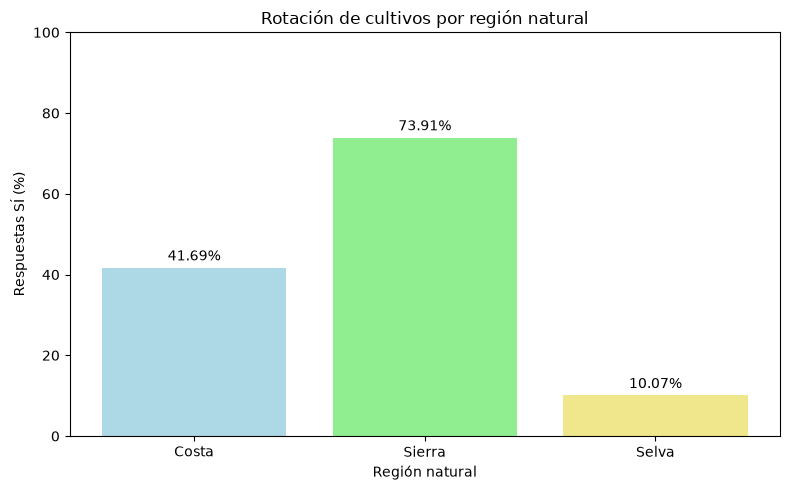

,Sí,No,Total válido,Porcentaje Sí
Costa,3649,5104,8753,41.69
Sierra,16571,5850,22421,73.91
Selva,726,6486,7212,10.07


In [112]:
# Traemos los datos del punto 7.2
regiones = tabla_rotacion_region.index
porcentajes = tabla_rotacion_region["Porcentaje Sí"]
totales = tabla_rotacion_region["Total válido"]

# Graficamos
plt.figure(figsize=(8, 5))
barras = plt.bar(regiones, porcentajes, color=["lightblue", "lightgreen", "khaki"])

plt.title("Rotación de cultivos por región natural")
plt.xlabel("Región natural")
plt.ylabel("Respuestas SÍ (%)")
plt.ylim(0, 100)

# Mostrar porcentajes
plt.bar_label(barras, fmt="%.2f%%", padding=2.9)

plt.tight_layout()
plt.show()

# Frecuencias y porcentajes utilizados
display(tabla_rotacion_region)

### 8.2. Comparación de prácticas

Comparamos los porcentajes de respuestas "Sí" de `8 prácticas agrícolas`. Excluimos `P301A_12B` del gráfico general porque sólo corresponde a Sierra.

In [113]:
# Seleccionar las prácticas con cobertura territorial general
practicas_grafico = resumen_practicas[resumen_practicas["codigo"]!="P301A_12B"].copy()

# Comprobar la selección
print("Prácticas seleccionadas:", len(practicas_grafico))
print("Prácticas excluidas:", set(resumen_practicas["codigo"])-set(practicas_grafico["codigo"]))

display(practicas_grafico[["codigo", "significado", "validas_1_2", "porcentaje_si"]])

Prácticas seleccionadas: 8
Prácticas excluidas: {'P301A_12B'}


,codigo,significado,validas_1_2,porcentaje_si
0,P301A_1,Análisis de suelos,38386,3.24
1,P301A_2,Mezclar la tierra con materia orgánica (rastro...,38386,60.72
2,P301A_3,Rotar los cultivos para proteger el suelo,38386,54.57
3,P301A_9,Determinar la cantidad de agua que necesita su...,38386,27.23
4,P301A_10,Determinar cada cuánto tiempo debe regar su cu...,38386,39.40
5,P301A_12A,Análisis de agua,38386,0.87
7,P301A_14,Usar fertilizantes,38386,57.58
8,P301A_15,"Usar plaguicidas como: insecticidas, fungicida...",38386,63.18


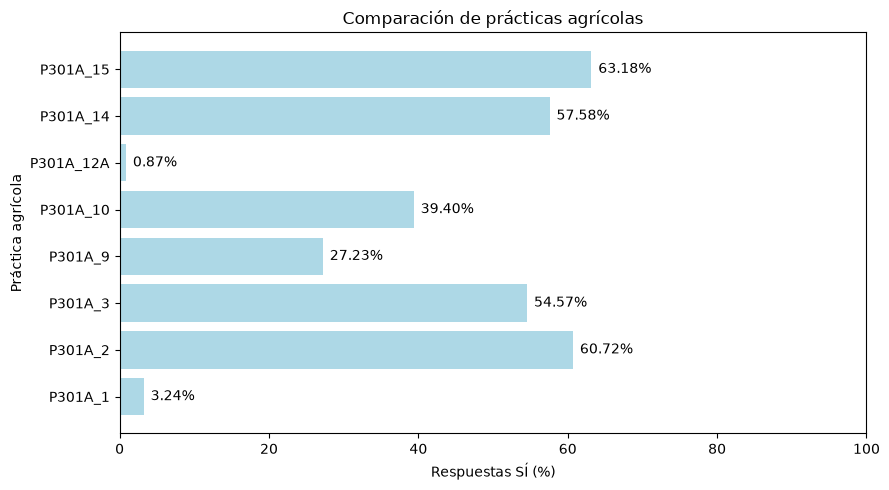

In [121]:
# Graficamos
plt.figure(figsize=(9, 5))
barras = plt.barh(practicas_grafico["codigo"], practicas_grafico["porcentaje_si"], color="lightblue")

plt.title("Comparación de prácticas agrícolas")
plt.xlabel("Respuestas SÍ (%)")
plt.ylabel("Práctica agrícola")
plt.xlim(0, 100)

# Mostrar porcentajes
plt.bar_label(barras, fmt="%.2f%%", padding=4.9)

plt.tight_layout()
plt.show()